# Evaluating cell segmentations without ground truth

Compares the cell segmentations of one `.zarr` (written by `macroseg.baseline`) using only the
channels used to segment: DAPI and the generic membrane marker.

**Looking at the data:** per-pixel histograms of DAPI and the membrane marker.

**Measures.** Each looks at one kind of error and has a blind spot, so read them together:

| Measure | Error it sees | Blind spot |
|---|---|---|
| Nuclei per cell | merged cells (2+), fragments or false cells (0), missed cells (nuclei in no cell) | not outlines; trivially perfect for grown nuclei |
| Border ratio | outline not on the membrane (ratio near 1) | favours segmentations that used the membrane channel |
| Shape (area, solidity) | abnormal objects (huge, ragged) | some cell types are genuinely irregular |

Optional: set `MARKER` to a population marker (e.g. `"F480"`) to add the marker separation measure.
Some cells without a nucleus are expected: the section is thinner than a cell.
CPU only.

In [8]:
from pathlib import Path

from spatialdata import read_zarr

from macroseg.config import load_config
from macroseg.evaluate import evaluate_candidates, plot_comparison
from macroseg.histograms import channel_summary, plot_histograms, sample_pixels

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
cfg = load_config(ROOT / "configs" / "exp201_test_crop.yaml")
sdata = read_zarr(cfg.zarr)
element = cfg.image.element

NUCLEI = "nuclei"          # reference nuclear segmentation
NUCLEAR_CHANNEL = "DAPI"
MEMBRANE = "NaK_ATPase"    # generic membrane marker
MARKER = "F480"              # optional population marker, e.g. "F480"
CANDIDATES = [step.labels for step in cfg.segmentation if step.labels != NUCLEI]
CANDIDATES

no parent found for <ome_zarr.reader.Label object at 0x12100a0b0>: None
no parent found for <ome_zarr.reader.Label object at 0x12100b230>: None
no parent found for <ome_zarr.reader.Label object at 0x11fe27d40>: None
no parent found for <ome_zarr.reader.Label object at 0x120430c50>: None
no parent found for <ome_zarr.reader.Label object at 0x1203c0050>: None
no parent found for <ome_zarr.reader.Label object at 0x11ff510d0>: None


['nuclei_expanded', 'membrane', 'membrane_dapi', 'membrane_dapi_f480']

## 1. Pixel histograms
Log axes; dashed lines at the 1st, 50th and 99th percentiles.

,p1,p50,p99,p99.9
DAPI,1137.0,18407.0,47392.0,56124.85
NaK_ATPase,288.0,1185.0,2409.0,2918.00
F480,0.0,80.0,1002.0,2455.00


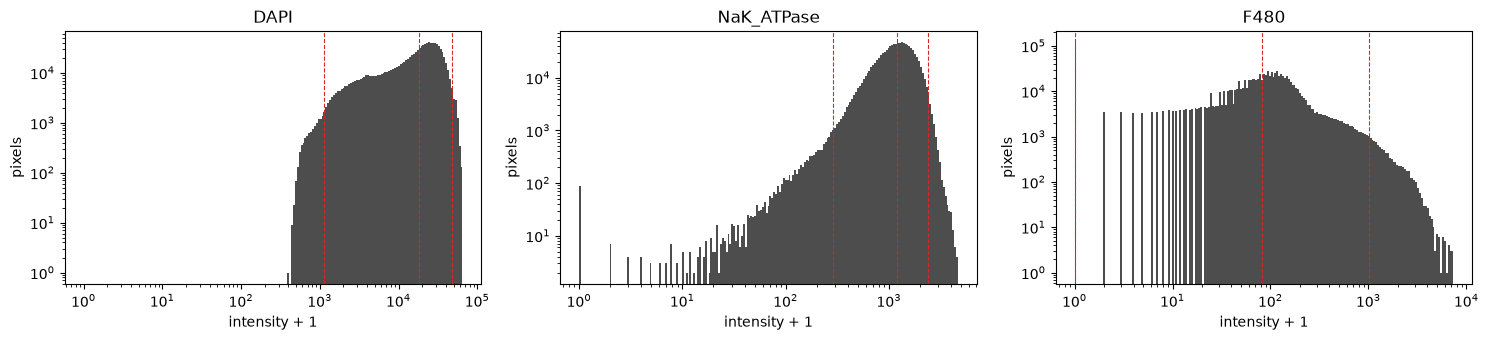

In [14]:
pixels = sample_pixels(sdata, element)
plot_histograms(pixels, channels=[NUCLEAR_CHANNEL, MEMBRANE, MARKER]);
channel_summary(pixels).loc[[NUCLEAR_CHANNEL, MEMBRANE, MARKER]]

## 2. Measures
One column per candidate. Percentages are of cells, except `nuclei_in_no_cell_%` (of nuclei).

In [10]:
summary, per_cell = evaluate_candidates(
    sdata, element, CANDIDATES, nuclei=NUCLEI, membrane=MEMBRANE, marker=MARKER
)
summary.T.round(2)

segmentation,nuclei_expanded,membrane,membrane_dapi,membrane_dapi_f480
cells,1911.00,1441.00,1587.00,1835.00
median_area_um2,57.80,66.64,66.41,58.03
cells_0_nuclei_%,0.00,16.17,6.36,10.30
cells_1_nucleus_%,100.00,63.84,80.34,81.25
cells_2plus_nuclei_%,0.00,19.99,13.30,8.45
nuclei_in_no_cell_%,0.00,18.16,9.63,4.87
median_border_ratio,1.19,1.30,1.24,1.24
median_solidity,0.94,0.93,0.94,0.94
F480_ashman_d,1.92,1.80,1.86,1.70
F480_ambiguous_%,4.81,4.93,4.66,5.34


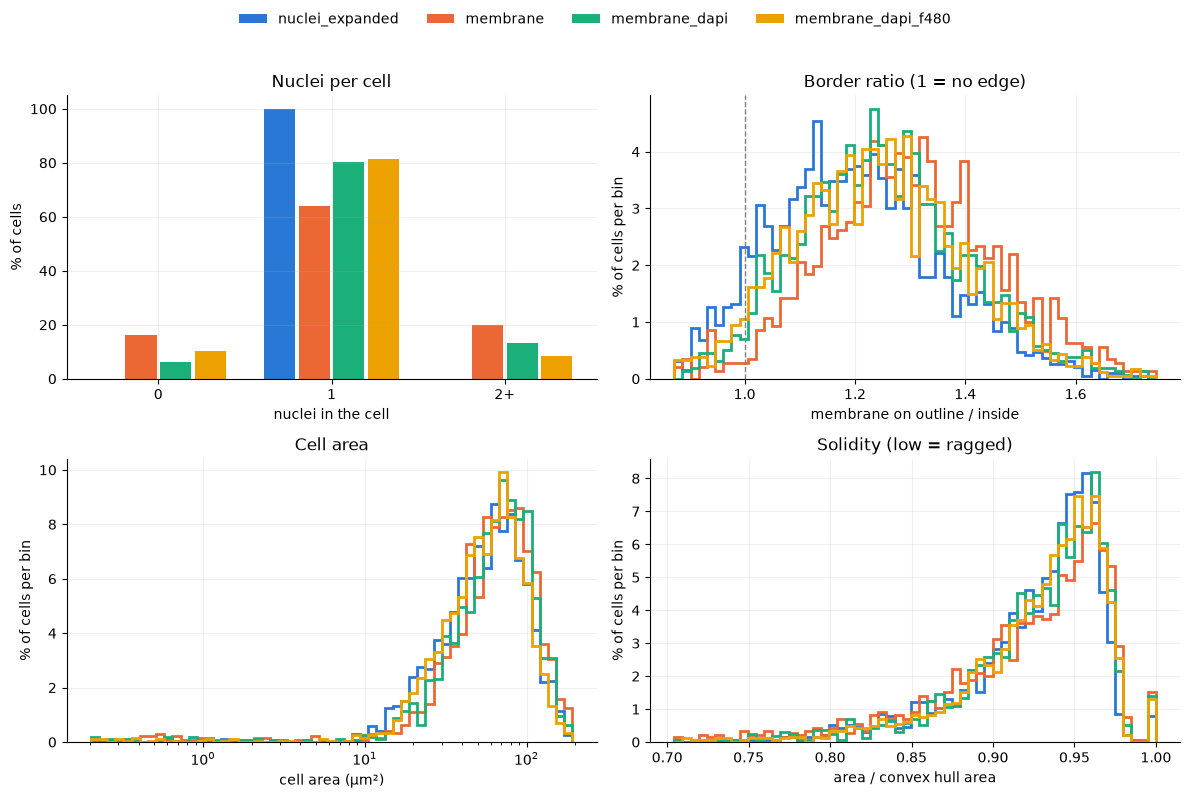

In [13]:
plot_comparison(per_cell, pixel_size_um=sdata.attrs["pixel_size_um"]);

## 3. Cells to look at
For example the largest cells with 2+ nuclei of one candidate (`cell_ID` is the value in its labels element).

In [12]:
name = CANDIDATES[-1]
per_cell[name].query("n_nuclei >= 2").sort_values("area", ascending=False).head(10)

,cell_ID,n_nuclei,border_ratio,area,solidity,eccentricity,marker_mean
1641,1845,2,1.441308,6691.0,0.922261,0.679263,86.910774
615,738,2,1.203887,6530.0,0.832165,0.824787,73.714088
152,240,2,1.189554,6371.0,0.895055,0.471205,69.066078
1463,1654,2,1.428182,5844.0,0.926149,0.638000,73.151779
290,389,2,1.312991,5716.0,0.954576,0.860252,70.572250
1213,1385,2,1.170802,5621.0,0.826132,0.798665,77.381424
135,222,2,1.189012,5408.0,0.971613,0.577927,73.014236
618,741,2,1.046199,5362.0,0.912992,0.690759,119.478180
1015,1172,3,1.015289,5211.0,0.946938,0.597801,1753.970215
313,416,2,1.255475,5159.0,0.856692,0.478735,75.679398
